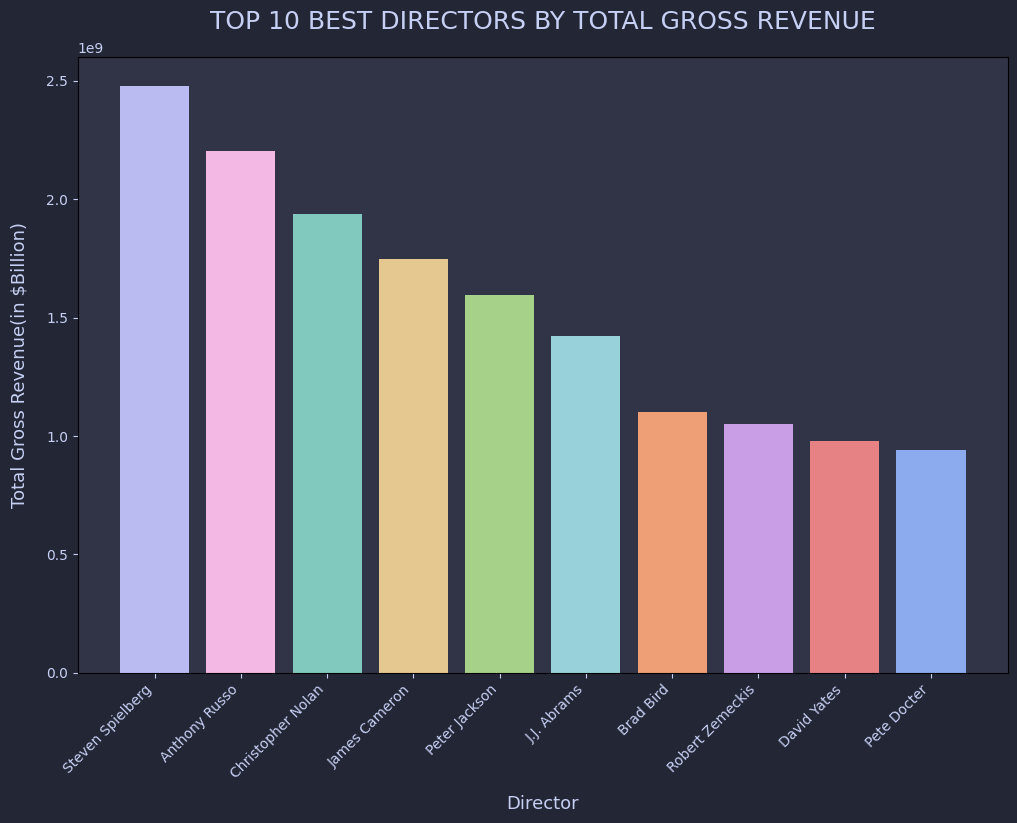

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("imdb_top_1000.csv")

# Data wrangling
data["Gross"] = data["Gross"].str.replace(',', '') # data cleaning: replaced all commas with empty strings to convert to numbers
data["Gross"] = pd.to_numeric(data['Gross'], errors = 'coerce') # converts the "Gross" column to numeric values, replacing any non-numeric entries with NaN.
gross_by_director = data.groupby('Director').agg({'Gross': 'sum', 'Director': 'count'}) #making separate table of directors by their total revenue and movie count
gross_by_director.columns = ['Gross', 'Movies'] # renames the columns to gross and movies
gross_by_director = gross_by_director[gross_by_director['Movies'] >= 3] # removes directors with less than 3 movies made

sorted_gross = gross_by_director.sort_values(by = "Gross", ascending = False) #sorts the table by gross in descending order
top10 = sorted_gross.head(10) # gets the top 10

# Plotting
colour = ['#babbf1','#f4b8e4','#81c8be','#e5c890','#a6d189','#99d1db','#ef9f76','#ca9ee6','#e78284','#8caaee']# list of hex color codes for plotting
plt.figure(figsize=(12, 8), facecolor='#232634')# create a 12x8 inch figure with dark background

plt.bar(top10.index, top10["Gross"], color=colour) # makes a bar graph
plt.gca().set_facecolor('#303446')# set the plot area background to dark gray
plt.tick_params(axis='both', colors='#c6d0f5', labelsize=10) # Changes the appearance of the scale (ticks and numbers) on both axes
plt.xticks(rotation=45, ha='right', color='#c6d0f5') # rotates director names for readability
plt.xlabel('Director', fontsize=13, color='#c6d0f5', labelpad=10) # labels the axis by director
plt.ylabel('Total Gross Revenue(in $Billion)', fontsize=13, color='#c6d0f5', labelpad=13) #labels the y axis by gross revenue
plt.title("TOP 10 BEST DIRECTORS BY TOTAL GROSS REVENUE", fontsize=18, color='#c6d0f5', pad=20) # Set main title of the plot

plt.show()# display the plot on screen